In [1]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import classification_report
from sklearn.svm import LinearSVC
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_validate

if Path.cwd().name == "src":
    os.chdir("..")

from src.data import load_dataset, TARGET_TAGS

In [2]:
df = load_dataset()


# Data Exploration

In [3]:
df.head()

,prob_desc_description,source_code,difficulty,tags
src_uid,,,,
591372383cf3624f69793c41370022de,"Numbers $$$1, 2, 3, \dots n$$$ (each integer f...",\ndef ii(): return int(input())\ndef mi(): ret...,1000.0,[math]
afcd41492158e68095b01ff1e88c3dd4,"There are $$$n$$$ positive integers $$$a_1, a_...",a = int(input())\nfor i in range(a):\n f = ...,1200.0,[number theory]
e52ec2fa5bcf5d2027d57b0694b4e15a,You are given an undirected graph consisting o...,def read_nums():\n return [int(x) for x in ...,1900.0,[graphs]
cd2519f4a7888b2c292f05c64a9db13a,A positive (strictly greater than zero) intege...,t = int(input())\nfor i in range(t):\n canP...,800.0,[math]
d7fe15a027750c004e4f50175e1e20d2,"Polycarp is working on a new project called ""P...",import sys\nz=x=0\nfor s in sys.stdin:\n\tif s...,1000.0,[]


In [5]:
print("Number of problems and duplicates : ", len(df), df.index.duplicated().sum())
print("Number of problems by tag : ")
print(df["tags"].explode().value_counts(dropna=False))
print("Part of problems with no tags : " , (df["tags"].str.len() == 0).mean())

Number of problems and duplicates :  4982 0
Number of problems by tag : 
tags
NaN              2304
math             1409
graphs            542
strings           422
number theory     350
trees             324
geometry          166
games             105
probabilities      92
Name: count, dtype: int64
Part of problems with no tags :  0.4624648735447611


46% of problems have no tags. We decide to keep them as some problems might not correspond to the provided tags. Our model should be able to predict it too. Some classes are unbalanced (for example, there are very few probabilities problems).

In [7]:
mlb = MultiLabelBinarizer(classes=TARGET_TAGS)
Y = mlb.fit_transform(df["tags"])

In [11]:
# Train test split with stratification on multilabels
msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(msss.split(df, Y))
df.drop("tags", inplace=True, axis=1)
train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
Y_train, Y_test = Y[train_idx], Y[test_idx]

C:\Users\addda\AppData\Local\Temp\ipykernel_24192\293812500.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop("tags", inplace=True, axis=1)


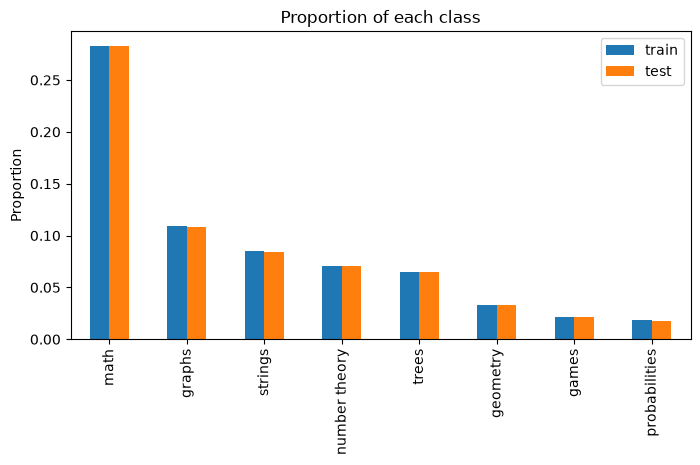

In [15]:
proportions = pd.DataFrame(
    {"train": Y_train.mean(axis=0), "test": Y_test.mean(axis=0)},
    index=TARGET_TAGS,
).sort_values("train", ascending=False)

ax = proportions.plot.bar(figsize=(8, 4))
ax.set_title("Proportion of each class")
ax.set_ylabel("Proportion")
plt.show()

# Model Training

In [16]:
# Logistic Regression model with TF-IDF features for both description and source code
model_logreg = Pipeline([
    ("features", ColumnTransformer([
        ("desc", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True),
         "prob_desc_description"),
        ("code", TfidfVectorizer(token_pattern=r"[A-Za-z_][A-Za-z0-9_]+", min_df=2, sublinear_tf=True),
         "source_code"),
    ])),
    ("clf", OneVsRestClassifier(LogisticRegression(max_iter=2000, class_weight="balanced"))),
])

# Logistic Regression model with TF-IDF features for both description and source code
model_svc = clone(model_logreg).set_params(
    clf=OneVsRestClassifier(LinearSVC(class_weight="balanced"))
)

In [17]:
scores_logreg = cross_validate(model_logreg, train_df, Y_train, cv=5, scoring=["f1_micro", "f1_macro"])
scores_svc = cross_validate(model_svc, train_df, Y_train, cv=5, scoring=["f1_micro", "f1_macro"])

pd.DataFrame({
    "logistic regression": {"f1_micro": scores_logreg["test_f1_micro"].mean(), "f1_macro": scores_logreg["test_f1_macro"].mean()},
    "linear svc": {"f1_micro": scores_svc["test_f1_micro"].mean(), "f1_macro": scores_svc["test_f1_macro"].mean()},
}).T.round(3)

,f1_micro,f1_macro
logistic regression,0.588,0.588
linear svc,0.551,0.557


In [ ]:
cols = ["prob_desc_description", "source_code"]
model_logreg.fit(train_df[cols].fillna(""), Y_train)
pred = model_logreg.predict(test_df[cols].fillna(""))

from sklearn.metrics import classification_report
print(classification_report(Y_test, pred, target_names=TARGET_TAGS, zero_division=0))

               precision    recall  f1-score   support

         math       0.56      0.62      0.59       282
       graphs       0.59      0.66      0.62       108
      strings       0.56      0.70      0.62        84
number theory       0.52      0.61      0.57        70
        trees       0.69      0.78      0.73        65
     geometry       0.64      0.64      0.64        33
        games       0.69      0.86      0.77        21
probabilities       0.67      0.22      0.33        18

    micro avg       0.58      0.65      0.61       681
    macro avg       0.61      0.64      0.61       681
 weighted avg       0.58      0.65      0.61       681
  samples avg       0.34      0.35      0.33       681



In [ ]:
model_svc.fit(train_df[cols].fillna(""), Y_train)
pred_svc = model_svc.predict(test_df[cols].fillna(""))

print(classification_report(Y_test, pred_svc, target_names=TARGET_TAGS, zero_division=0))

               precision    recall  f1-score   support

         math       0.58      0.52      0.55       282
       graphs       0.61      0.50      0.55       108
      strings       0.62      0.56      0.59        84
number theory       0.71      0.53      0.61        70
        trees       0.84      0.74      0.79        65
     geometry       0.78      0.55      0.64        33
        games       0.84      0.76      0.80        21
probabilities       0.75      0.17      0.27        18

    micro avg       0.65      0.54      0.59       681
    macro avg       0.72      0.54      0.60       681
 weighted avg       0.65      0.54      0.59       681
  samples avg       0.31      0.30      0.29       681



# Embeddings Sentence Transformers + Classifier

In [19]:
from sentence_transformers import SentenceTransformer
import numpy as np

c:\Users\addda\Documents\Projets Persos\illuin-test\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [20]:
encoder = SentenceTransformer("BAAI/bge-small-en-v1.5")

X_desc = encoder.encode(
    df["prob_desc_description"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
)
print(X_desc.shape) 

Batches: 100%|██████████| 156/156 [06:51<00:00,  2.64s/it]

(4982, 384)


In [23]:
np.save("X_desc_bge_small.npy", X_desc) 

In [24]:
X_emb = np.load("X_desc_bge_small.npy")

# Mêmes lignes train/test que pour le TF-IDF
train_pos = df.index.get_indexer(train_df.index)
test_pos  = df.index.get_indexer(test_df.index)

clf = OneVsRestClassifier(LogisticRegression(max_iter=2000, class_weight="balanced"))
clf.fit(X_emb[train_pos], Y_train)
pred_emb = clf.predict(X_emb[test_pos])

print(classification_report(Y_test, pred_emb, target_names=TARGET_TAGS, zero_division=0))

               precision    recall  f1-score   support

         math       0.44      0.65      0.52       282
       graphs       0.34      0.71      0.46       108
      strings       0.49      0.83      0.62        84
number theory       0.25      0.73      0.37        70
        trees       0.38      0.74      0.50        65
     geometry       0.26      0.79      0.39        33
        games       0.38      0.90      0.54        21
probabilities       0.16      0.72      0.26        18

    micro avg       0.36      0.71      0.48       681
    macro avg       0.34      0.76      0.46       681
 weighted avg       0.39      0.71      0.49       681
  samples avg       0.29      0.39      0.32       681



Worse results

# Zero-shot LLM with Groq
No training: the LLM reads the statement and picks tags among the 8. The API key is read from `.env` (`GROQ_API_KEY`).

In [ ]:
from typing import Literal

from dotenv import load_dotenv
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_groq import ChatGroq
from pydantic import BaseModel
from tqdm.auto import tqdm

load_dotenv()  # Loads GROQ_API_KEY from .env, the key is never written in the notebook


class Tags(BaseModel):
    tags: list[Literal[tuple(TARGET_TAGS)]]  # The LLM can only answer tags among the 8, possibly none


# Free tier allows 8000 tokens/min (~24 requests): we send ~20 requests/min evenly to never hit the limit
rate_limiter = InMemoryRateLimiter(requests_per_second=20 / 60)

# json_mode instead of tool calling: Qwen sometimes calls the tool with a wrong name
llm = ChatGroq(
    model="qwen/qwen3.8-27b", temperature=0, reasoning_effort="none", max_retries=5, rate_limiter=rate_limiter
).with_structured_output(Tags, method="json_mode")

PROMPT = """You classify competitive programming problems from Codeforces.
Possible tags: {tags}.
Return only the tags that clearly apply to the problem. Return an empty list if none apply.
Answer in JSON with this format: {{"tags": ["tag1", "tag2"]}}

Problem statement:
{description}"""

In [28]:
# Free Groq tier is rate limited, so we only compare on 20 test exercises
sample_pos = np.random.default_rng(42).choice(len(test_df), size=20, replace=False)
sample = test_df.iloc[sample_pos]

pred_llm = []
for description in tqdm(sample["prob_desc_description"]):
    answer = llm.invoke(PROMPT.format(tags=", ".join(TARGET_TAGS), description=description[:3000]))
    pred_llm.append(answer.tags)
pred_llm = mlb.transform(pred_llm)

print("LLM zero-shot")
print(classification_report(Y_test[sample_pos], pred_llm, target_names=TARGET_TAGS, zero_division=0))
print("TF-IDF + Logistic Regression on the same 20 exercises")
print(classification_report(Y_test[sample_pos], pred[sample_pos], target_names=TARGET_TAGS, zero_division=0))

  0%|          | 0/100 [00:00<?, ?it/s]


NotFoundError: Error code: 404 - {'error': {'message': 'The model `qwen/qwen3-32b` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}